# Spam text message classification

**Student:** Hadar Cywyak  
**Last four ID digits:** 4978  
**Learning task:** supervised binary classification  
**Algorithm:** Multinomial Naive Bayes

## 1. Introduction
The goal is to classify text messages as spam or ham (normal messages). The dataset contains 5,572 messages with two columns: `Category` and `Message`. Word counts represent the messages, and a Multinomial Naive Bayes classifier predicts their category. Spam is the positive class. The main evaluation metric is spam F1 because most messages are ham, making accuracy alone insufficient.

**Dataset:** https://www.kaggle.com/datasets/team-ai/spam-text-message-classification

### AI assistance
**AI agent:**  Gemini   
**Goal:** Help with syntax for CountVectorizer, writing Naive Bayes with NumPy, and organizing the cross-validation loop.

- **Prompt 1:** "How do I use CountVectorizer in sklearn and print the words and their counts for the first 3 rows?"
- **Prompt 2:** "How can I implement Multinomial Naive Bayes from scratch in Python using numpy and log probabilities?"
- **Prompt 3:** "How do I write a 5-fold cross validation loop in Python to test different hyperparameter combinations and save the results in a DataFrame?"

### Dependencies
NumPy, pandas, matplotlib, SciPy and scikit-learn. The input file is `SPAM text message 20170820 - Data.csv`.

In [1]:
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (f1_score, precision_score, recall_score,
                             accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay)

SEED = 42
pd.set_option('display.max_colwidth', 100)

### Data preparation
The dataset is provided as a single CSV without predefined training and test sets. After removing duplicate messages, the data is split once into 80% training and 20% testing, with a fixed random seed of 42. Stratification preserves approximately the same class proportions in both sets.

The dataset contains no missing values. Removing 415 duplicate messages leaves 5,157 examples and prevents identical messages from appearing in both sets.

In [2]:
filename = 'SPAM text message 20170820 - Data.csv'
data_path = Path(filename)
if not data_path.exists():
    data_path = Path('upload') / filename
if not data_path.exists():
    raise FileNotFoundError('Upload the supplied CSV or place it next to this notebook.')

raw = pd.read_csv(data_path)
print('Original shape:', raw.shape)
display(raw.head())
print('Missing values:')
print(raw.isna().sum())
print('Exact duplicate rows:', raw.duplicated().sum())

data = raw.dropna(subset=['Category', 'Message']).copy()
assert set(data['Category']) == {'ham', 'spam'}
assert data.groupby('Message')['Category'].nunique().max() == 1, 'Conflicting labels'
data = data.drop_duplicates(subset='Message').reset_index(drop=True)
data['label'] = data['Category'].map({'ham': 0, 'spam': 1})
print('Shape after cleaning:', data.shape)
display(data['Category'].value_counts().rename('Messages').to_frame())

Original shape: (5572, 2)
Missing values:
Category    0
Message     0
dtype: int64
Exact duplicate rows: 415
Shape after cleaning: (5157, 3)


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there g..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive ...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


,Messages
Category,
ham,4516
spam,641


In [3]:
train_df, test_df = train_test_split(
    data, test_size=0.20, random_state=SEED, stratify=data['label']
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
assert set(train_df['Message']).isdisjoint(set(test_df['Message']))

print('First 5 training examples:')
display(train_df.head())
print('First 5 test examples:')
display(test_df.head())
display(pd.DataFrame({
    'train': train_df['Category'].value_counts(),
    'test': test_df['Category'].value_counts()
}))

First 5 training examples:
First 5 test examples:


,Category,Message,label
0,ham,Saw Guys and Dolls last night with Patrick Swayze it was great,0
1,ham,Nothing but we jus tot u would ask cos u ba gua... But we went mt faber yest... Yest jus went ou...,0
2,ham,Oh really?? Did you make it on air? What's your talent?,0
3,spam,"TheMob>Hit the link to get a premium Pink Panther game, the new no. 1 from Sugababes, a crazy Ze...",1
4,spam,"New Mobiles from 2004, MUST GO! Txt: NOKIA to No: 89545 & collect yours today! From ONLY £1. www...",1


,Category,Message,label
0,ham,Can you plz tell me the ans. BSLVYL sent via fullonsms.com,0
1,ham,You intrepid duo you! Have a great time and see you both soon.,0
2,ham,R u in this continent?,0
3,ham,"Cool, want me to go to kappa or should I meet you outside mu",0
4,ham,I'm meeting Darren...,0


,train,test
Category,,
ham,3612,904
spam,513,128


## 2. Feature engineering: bag-of-words
`CountVectorizer` converts each message into token counts. Text is lowercased, and each vocabulary token becomes a feature. The default token rule keeps tokens of at least two characters, ignores punctuation and allows numeric tokens. Stop words are retained because common words may still be useful in short messages.

For example, “free free prize” gives a count of 2 for “free” and 1 for “prize”. The matrix is sparse because each message contains only a small part of the vocabulary. Single-word features ignore word order; bigrams also represent pairs of consecutive tokens.

The vocabulary is fitted on training data only. Test messages use the same vocabulary, and unknown tokens are ignored. Three examples from each set show the tokenization and nonzero features. During cross-validation, a separate vocabulary is fitted within each training fold.

In [4]:
def show_features(vectorizer, frame, n=3):
    matrix = vectorizer.transform(frame['Message'].iloc[:n])
    words = vectorizer.get_feature_names_out()
    rows = []
    for i in range(n):
        row = matrix.getrow(i)
        counts = {words[j]: int(v) for j, v in zip(row.indices, row.data)}
        rows.append({
            'message': frame.iloc[i]['Message'],
            'tokens': vectorizer.build_analyzer()(frame.iloc[i]['Message']),
            'nonzero features': counts
        })
    with pd.option_context('display.max_colwidth', None):
        display(pd.DataFrame(rows))

demo_vectorizer = CountVectorizer()
demo_vectorizer.fit(train_df['Message'])
print('Training vocabulary size:', len(demo_vectorizer.vocabulary_))
print('3 training examples:')
show_features(demo_vectorizer, train_df)
print('3 test examples:')
show_features(demo_vectorizer, test_df)

Training vocabulary size: 7674
3 training examples:
3 test examples:


,message,tokens,nonzero features
0,Saw Guys and Dolls last night with Patrick Swayze it was great,"[saw, guys, and, dolls, last, night, with, patrick, swayze, it, was, great]","{'and': 1, 'dolls': 1, 'great': 1, 'guys': 1, 'it': 1, 'last': 1, 'night': 1, 'patrick': 1, 'saw': 1, 'swayze': 1, 'was': 1, 'with': 1}"
1,Nothing but we jus tot u would ask cos u ba gua... But we went mt faber yest... Yest jus went out already mah so today not going out... Jus call lor...,"[nothing, but, we, jus, tot, would, ask, cos, ba, gua, but, we, went, mt, faber, yest, yest, jus, went, out, already, mah, so, today, not, going, out, jus, call, lor]","{'already': 1, 'ask': 1, 'ba': 1, 'but': 2, 'call': 1, 'cos': 1, 'faber': 1, 'going': 1, 'gua': 1, 'jus': 3, 'lor': 1, 'mah': 1, 'mt': 1, 'not': 1, 'nothing': 1, 'out': 2, 'so': 1, 'today': 1, 'tot': 1, 'we': 2, 'went': 2, 'would': 1, 'yest': 2}"
2,Oh really?? Did you make it on air? What's your talent?,"[oh, really, did, you, make, it, on, air, what, your, talent]","{'air': 1, 'did': 1, 'it': 1, 'make': 1, 'oh': 1, 'on': 1, 'really': 1, 'talent': 1, 'what': 1, 'you': 1, 'your': 1}"


,message,tokens,nonzero features
0,Can you plz tell me the ans. BSLVYL sent via fullonsms.com,"[can, you, plz, tell, me, the, ans, bslvyl, sent, via, fullonsms, com]","{'ans': 1, 'bslvyl': 1, 'can': 1, 'com': 1, 'fullonsms': 1, 'me': 1, 'plz': 1, 'sent': 1, 'tell': 1, 'the': 1, 'via': 1, 'you': 1}"
1,You intrepid duo you! Have a great time and see you both soon.,"[you, intrepid, duo, you, have, great, time, and, see, you, both, soon]","{'and': 1, 'both': 1, 'great': 1, 'have': 1, 'see': 1, 'soon': 1, 'time': 1, 'you': 3}"
2,R u in this continent?,"[in, this, continent]","{'in': 1, 'this': 1}"


## 3. Implementing Multinomial Naive Bayes
Naive Bayes estimates how likely each word is in each class. It assumes that word occurrences are conditionally independent given the class. That is a simplification: words in real messages are related.

During `fit`, the model counts the messages in each class and adds up the word counts for that class. For word $j$ and class $c$:

$$P(w_j\mid c)=\frac{N_{cj}+\alpha}{\sum_k N_{ck}+\alpha V}$$

Here $N_{cj}$ is the word count, $V$ is vocabulary size, and `alpha` is smoothing. A positive `alpha` prevents unseen words in a class from getting probability zero. A larger value smooths the probabilities more strongly.

During `predict`, it computes the following score for each class and chooses the larger one:

$$\log P(c)+\sum_j x_j\log P(w_j\mid c)$$

Using logs avoids multiplying many tiny probabilities. The class prior $P(c)$ is the fraction of training messages in that class. The classifier is implemented with NumPy and sparse matrix operations; it does not use a ready-made Naive Bayes classifier. scikit-learn is used for text features, splits and metrics.

In [5]:
class MultinomialNB:
    def __init__(self, alpha=1.0):
        if alpha <= 0:
            raise ValueError('alpha must be positive')
        self.alpha = alpha

    def fit(self, X, y):
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        class_counts = np.array([(y == c).sum() for c in self.classes_])
        self.class_log_prior_ = np.log(class_counts / len(y))

        word_counts = np.vstack([
            np.asarray(X[y == c].sum(axis=0)).ravel()
            for c in self.classes_
        ])
        smoothed_counts = word_counts + self.alpha
        word_probabilities = smoothed_counts / smoothed_counts.sum(axis=1, keepdims=True)
        self.feature_log_prob_ = np.log(word_probabilities)
        return self

    def predict(self, X):
        scores = X @ self.feature_log_prob_.T + self.class_log_prior_
        return self.classes_[np.asarray(scores).argmax(axis=1)]

## 6. Extension: grid search with 5-fold cross-validation
Parameter selection uses only the training set and takes place before final training. The grid contains:

- `ngram_range`: `(1, 1)` for single words or `(1, 2)` for single words and bigrams.
- `min_df`: 1 or 2, the minimum number of training messages containing a token.
- `alpha`: 0.5 or 1.0, the smoothing parameter.

The full Cartesian product gives eight combinations. Each combination is evaluated on five folds, for a total of 40 fits. Stratification keeps similar class proportions in each fold. The vectorizer is fitted only on the training portion of each fold.

The combination with the highest mean validation spam F1 is selected. The test set is excluded from parameter selection.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results = []

for ngram_range, min_df, alpha in product([(1, 1), (1, 2)], [1, 2], [0.5, 1.0]):
    fold_scores = []
    for train_indices, val_indices in cv.split(train_df['Message'], train_df['label']):
        fold_train = train_df.iloc[train_indices]
        fold_val = train_df.iloc[val_indices]

        vectorizer = CountVectorizer(ngram_range=ngram_range, min_df=min_df)
        X_fold_train = vectorizer.fit_transform(fold_train['Message'])
        X_fold_val = vectorizer.transform(fold_val['Message'])

        model = MultinomialNB(alpha=alpha)
        model.fit(X_fold_train, fold_train['label'])
        predictions = model.predict(X_fold_val)
        fold_scores.append(f1_score(fold_val['label'], predictions, pos_label=1))

    results.append({
        'ngram_range': ngram_range, 'min_df': min_df, 'alpha': alpha,
        **{f'fold_{i+1}': score for i, score in enumerate(fold_scores)},
        'mean_spam_f1': np.mean(fold_scores),
        'std_spam_f1': np.std(fold_scores)
    })

results_df = pd.DataFrame(results).sort_values('mean_spam_f1', ascending=False, kind='stable')
display(results_df.reset_index(drop=True).round(4))
best = results_df.iloc[0]
print('Best combination:')
print('ngram_range =', best['ngram_range'])
print('min_df =', int(best['min_df']))
print('alpha =', best['alpha'])
print(f"Mean validation spam F1 = {best['mean_spam_f1']:.4f}")

Best combination:
ngram_range = (1, 2)
min_df = 1
alpha = 0.5
Mean validation spam F1 = 0.9435


,ngram_range,min_df,alpha,fold_1,fold_2,fold_3,fold_4,fold_5,mean_spam_f1,std_spam_f1
0,"(1, 2)",1,0.5,0.9442,0.9340,0.9648,0.9412,0.9333,0.9435,0.0114
1,"(1, 1)",2,0.5,0.9400,0.9300,0.9604,0.9314,0.9505,0.9425,0.0116
2,"(1, 1)",1,0.5,0.9347,0.9254,0.9703,0.9320,0.9447,0.9414,0.0157
3,"(1, 2)",1,1.0,0.9333,0.9271,0.9543,0.9500,0.9333,0.9396,0.0106
4,"(1, 2)",2,1.0,0.9388,0.9340,0.9500,0.9307,0.9388,0.9385,0.0065
5,"(1, 2)",2,0.5,0.9300,0.9300,0.9505,0.9314,0.9495,0.9383,0.0096
6,"(1, 1)",2,1.0,0.9400,0.9154,0.9652,0.9223,0.9453,0.9376,0.0176
7,"(1, 1)",1,1.0,0.9333,0.9192,0.9600,0.9360,0.9388,0.9375,0.0131


## 4. Final training
A new vectorizer and classifier are fitted on all 4,125 training messages using the selected settings. `fit_transform` learns the training vocabulary, while `transform` applies it to the 1,032 test messages. Three examples from each set show the final feature representation.

In [7]:
final_vectorizer = CountVectorizer(
    ngram_range=best['ngram_range'], min_df=int(best['min_df'])
)
X_train = final_vectorizer.fit_transform(train_df['Message'])
X_test = final_vectorizer.transform(test_df['Message'])
y_train = train_df['label'].to_numpy()
y_test = test_df['label'].to_numpy()

final_model = MultinomialNB(alpha=float(best['alpha']))
final_model.fit(X_train, y_train)
print('Training matrix:', X_train.shape)
print('Test matrix:', X_test.shape)
print('Final training examples:')
show_features(final_vectorizer, train_df)
print('Final test examples:')
show_features(final_vectorizer, test_df)

Training matrix: (4125, 42593)
Test matrix: (1032, 42593)
Final training examples:
Final test examples:


,message,tokens,nonzero features
0,Saw Guys and Dolls last night with Patrick Swayze it was great,"[saw, guys, and, dolls, last, night, with, patrick, swayze, it, was, great, saw guys, guys and, and dolls, dolls last, last night, night with, with patrick, patrick swayze, swayze it, it was, was great]","{'and': 1, 'and dolls': 1, 'dolls': 1, 'dolls last': 1, 'great': 1, 'guys': 1, 'guys and': 1, 'it': 1, 'it was': 1, 'last': 1, 'last night': 1, 'night': 1, 'night with': 1, 'patrick': 1, 'patrick swayze': 1, 'saw': 1, 'saw guys': 1, 'swayze': 1, 'swayze it': 1, 'was': 1, 'was great': 1, 'with': 1, 'with patrick': 1}"
1,Nothing but we jus tot u would ask cos u ba gua... But we went mt faber yest... Yest jus went out already mah so today not going out... Jus call lor...,"[nothing, but, we, jus, tot, would, ask, cos, ba, gua, but, we, went, mt, faber, yest, yest, jus, went, out, already, mah, so, today, not, going, out, jus, call, lor, nothing but, but we, we jus, jus tot, tot would, would ask, ask cos, cos ba, ba gua, gua but, but we, we went, went mt, mt faber, faber yest, yest yest, yest jus, jus went, went out, out already, already mah, mah so, so today, today not, not going, going out, out jus, jus call, call lor]","{'already': 1, 'already mah': 1, 'ask': 1, 'ask cos': 1, 'ba': 1, 'ba gua': 1, 'but': 2, 'but we': 2, 'call': 1, 'call lor': 1, 'cos': 1, 'cos ba': 1, 'faber': 1, 'faber yest': 1, 'going': 1, 'going out': 1, 'gua': 1, 'gua but': 1, 'jus': 3, 'jus call': 1, 'jus tot': 1, 'jus went': 1, 'lor': 1, 'mah': 1, 'mah so': 1, 'mt': 1, 'mt faber': 1, 'not': 1, 'not going': 1, 'nothing': 1, 'nothing but': 1, 'out': 2, 'out already': 1, 'out jus': 1, 'so': 1, 'so today': 1, 'today': 1, 'today not': 1, 'tot': 1, 'tot would': 1, 'we': 2, 'we jus': 1, 'we went': 1, 'went': 2, 'went mt': 1, 'went out': 1, 'would': 1, 'would ask': 1, 'yest': 2, 'yest jus': 1, 'yest yest': 1}"
2,Oh really?? Did you make it on air? What's your talent?,"[oh, really, did, you, make, it, on, air, what, your, talent, oh really, really did, did you, you make, make it, it on, on air, air what, what your, your talent]","{'air': 1, 'air what': 1, 'did': 1, 'did you': 1, 'it': 1, 'it on': 1, 'make': 1, 'make it': 1, 'oh': 1, 'oh really': 1, 'on': 1, 'on air': 1, 'really': 1, 'really did': 1, 'talent': 1, 'what': 1, 'what your': 1, 'you': 1, 'you make': 1, 'your': 1, 'your talent': 1}"


,message,tokens,nonzero features
0,Can you plz tell me the ans. BSLVYL sent via fullonsms.com,"[can, you, plz, tell, me, the, ans, bslvyl, sent, via, fullonsms, com, can you, you plz, plz tell, tell me, me the, the ans, ans bslvyl, bslvyl sent, sent via, via fullonsms, fullonsms com]","{'ans': 1, 'bslvyl': 1, 'can': 1, 'can you': 1, 'com': 1, 'fullonsms': 1, 'fullonsms com': 1, 'me': 1, 'me the': 1, 'plz': 1, 'sent': 1, 'sent via': 1, 'tell': 1, 'tell me': 1, 'the': 1, 'via': 1, 'via fullonsms': 1, 'you': 1, 'you plz': 1}"
1,You intrepid duo you! Have a great time and see you both soon.,"[you, intrepid, duo, you, have, great, time, and, see, you, both, soon, you intrepid, intrepid duo, duo you, you have, have great, great time, time and, and see, see you, you both, both soon]","{'and': 1, 'and see': 1, 'both': 1, 'great': 1, 'great time': 1, 'have': 1, 'have great': 1, 'see': 1, 'see you': 1, 'soon': 1, 'time': 1, 'you': 3, 'you both': 1, 'you have': 1}"
2,R u in this continent?,"[in, this, continent, in this, this continent]","{'in': 1, 'in this': 1, 'this': 1}"


## 5. Predictions and test evaluation
Spam is encoded as 1 and ham as 0. Spam precision is the proportion of predicted spam messages that are actually spam. Spam recall is the proportion of actual spam messages detected by the model.

$$F1=\frac{2\cdot\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$$

F1 is the harmonic mean of precision and recall. Accuracy is included as a secondary metric. An always-ham baseline provides a comparison. Evaluation uses the held-out test set after parameter selection and final training.

First 5 test predictions:
Correct ham: 901; false spam alarms: 3
Missed spam: 17; correctly detected spam: 111


,Message,Category,prediction
0,Can you plz tell me the ans. BSLVYL sent via fullonsms.com,ham,ham
1,You intrepid duo you! Have a great time and see you both soon.,ham,ham
2,R u in this continent?,ham,ham
3,"Cool, want me to go to kappa or should I meet you outside mu",ham,ham
4,I'm meeting Darren...,ham,ham


,Spam precision,Spam recall,Spam F1,Accuracy
Naive Bayes,0.9737,0.8672,0.9174,0.9806
Always ham,0.0000,0.0000,0.0000,0.8760


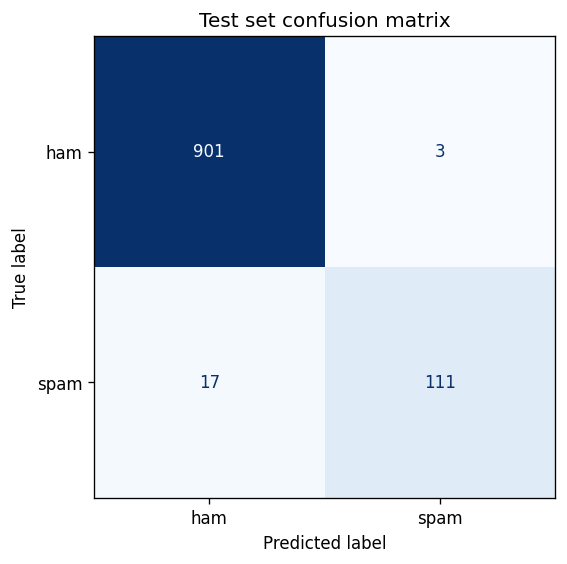

In [8]:
y_pred = final_model.predict(X_test)
first_five = test_df[['Message', 'Category']].head().copy()
first_five['prediction'] = np.where(y_pred[:5] == 1, 'spam', 'ham')
print('First 5 test predictions:')
display(first_five)

def evaluate(y_true, predictions):
    return {
        'Spam precision': precision_score(y_true, predictions, zero_division=0),
        'Spam recall': recall_score(y_true, predictions, zero_division=0),
        'Spam F1': f1_score(y_true, predictions, zero_division=0),
        'Accuracy': accuracy_score(y_true, predictions)
    }

metrics = evaluate(y_test, y_pred)
display(pd.DataFrame({
    'Naive Bayes': metrics,
    'Always ham': evaluate(y_test, np.zeros_like(y_test))
}).T.round(4))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=['ham', 'spam']).plot(cmap='Blues', colorbar=False)
plt.title('Test set confusion matrix')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'Correct ham: {tn}; false spam alarms: {fp}')
print(f'Missed spam: {fn}; correctly detected spam: {tp}')

### Misclassified messages
False positives are normal messages classified as spam. False negatives are spam messages classified as ham. Up to three examples of each error type are shown. These examples are used for error analysis, not further parameter selection.

In [9]:
errors = test_df[['Message', 'Category']].copy()
errors['prediction'] = np.where(y_pred == 1, 'spam', 'ham')
print('False positives (up to 3):')
display(errors[(y_test == 0) & (y_pred == 1)].head(3))
print('False negatives (up to 3):')
display(errors[(y_test == 1) & (y_pred == 0)].head(3))

False positives (up to 3):
False negatives (up to 3):


,Message,Category,prediction
421,I'm vivek:)i got call from your number.,ham,spam
621,Dont you have message offer,ham,spam
706,Unlimited texts. Limited minutes.,ham,spam


,Message,Category,prediction
63,You will be receiving this week's Triple Echo ringtone shortly. Enjoy it!,spam,ham
114,Can U get 2 phone NOW? I wanna chat 2 set up meet Call me NOW on 09096102316 U can cum here 2mor...,spam,ham
217,"Oh my god! I've found your number again! I'm so glad, text me back xafter this msgs cst std ntwk...",spam,ham


## Conclusion
The selected model uses single words and bigrams, `min_df = 1` and `alpha = 0.5`. Its mean cross-validation spam F1 is 0.9435. On the test set, spam F1 is 0.9174, precision is 0.9737 and recall is 0.8672. It correctly detects 111 spam messages, misses 17 and incorrectly flags 3 normal messages.

The always-ham baseline misses every spam message despite having high accuracy. Spam F1 therefore gives a more useful measure for this task.

Naive Bayes is quick to train but relies on a simplified independence assumption. Bigrams capture some local word order, while unfamiliar spelling and unknown tokens can cause errors. Exact duplicates were removed, although similar templates may remain. Results from this random split may not generalize to messages from other time periods or languages.

In [10]:
print(f"Final test spam F1: {metrics['Spam F1']:.4f}")
print(f"Spam precision: {metrics['Spam precision']:.4f}")
print(f"Spam recall: {metrics['Spam recall']:.4f}")
print(f'The model missed {fn} spam messages and incorrectly flagged {fp} normal messages.')

Final test spam F1: 0.9174
Spam precision: 0.9737
Spam recall: 0.8672
The model missed 17 spam messages and incorrectly flagged 3 normal messages.
